In [1]:
import numpy as np
from pathlib import Path
import pandas as pd
import sys
sys.path.insert(1, '../../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model, k_risk

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc
import seaborn as sns

font = {'size':10}
mpl.rc('font', **font)

### Data_processing to get to df_TEs, T_lims, betas, q_c, q_r and the interaction matrices A

In [2]:
%run Data_processing.py

In [74]:
print(scenarios)

['CurPol_SAP' 'CurPol_OS_1.5C' 'ModAct_OS_1.5C' 'ModAct_OS_1C'
 'ModAct_SAP' 'ssp534-over' 'Neg_SAP' 'GS_NZGHG' 'Ren_NZCO2' 'Neg_NZGHG'
 'Ref_1p5' 'Neg_OS_0C' 'LD_NZGHG' 'SP_NZGHG' 'ssp119']


# Simulations

### Baseline temperature scenario: actual + fitted parameters

In [32]:
baseline = 'ssp534-over'#'ModAct_OS_1.5C'
baseline_disp = baseline#'SSP5-3.4-OS'

if baseline == 'ssp126':
    df_ipcc = pd.read_excel('../../../Data/extendedSSPs.xlsx')
    temp = df_ipcc[df_ipcc['scenario']=='ssp126'].set_index('quantile').iloc[:,9:].transpose()['median'].to_numpy()
else:
    temp = df[baseline].to_numpy()
t_ref=2015
T_ref=temp[t_ref-1850]
T_max=temp.max()
xdata = np.arange(t_ref,1850+len(temp))-t_ref
ydata=temp[t_ref-1850:]
popt, pcov = curve_fit(OS_model, xdata, ydata,
                       p0=[T_ref, T_max, temp[-1], (T_max-T_ref)/0.01, 10 ,(temp.max()-T_ref)/0.01],
                       bounds = ([T_ref-0.5, T_max-0.5, temp[-1]-0.5, 10, 0, 10],
                                 [T_ref+0.5, T_max+0.5, temp[-1]+0.5, len(ydata), 100, len(ydata)]) )

data_folder = '../../../Data/Simulations/Overshoots/%s/OAT'%baseline
# if os.p
if not os.path.isdir(data_folder[:-4]):
    os.mkdir(data_folder[:-4])
if not os.path.isdir(data_folder[:-4]+'/Baseline'):
    os.mkdir(data_folder[:-4]+'/Baseline')
if not os.path.isdir(data_folder):
    os.mkdir(data_folder)
# np.savetxt(data_folder[:-4]+'/Baseline/popt.txt',popt)

#### checking T_p = 1.95 and T_s = 1.35

In [33]:
### BASELINE SIMULATIONS
years = np.arange(1850,1850+len(temp))
no_years = len(years)
# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((no_years,len(df_TEs)))
p_c *= q_c

p_r = np.ones((no_years,len(df_TEs)))
p_r *= q_r

for t in range(no_years):
    p_c[t,:] *= temp_response(temp[t], T_lim, betas)
    p_r[t,:] *= (1-temp_response(temp[t], T_lim, betas))

D_baseline = np.zeros((len_sample,len(df_TEs),no_years))
for r in range(len_sample):
    for t in range(1,no_years):
        D_baseline[r,:,t] = environmental_update(D_baseline[r,:,t-1],A[r],pc=p_c[t,:],pr=p_r[t,:])

### SENSITIVITY ANALYSIS
## Burn in with historical data (up to and inc. 2015)
years_burn_in = np.arange(1850,2016) # up to and including 2015
no_burn_years = len(years_burn_in)
pc_burn = np.ones((no_burn_years,len(df_TEs)))
pc_burn *= q_c
pr_burn = np.ones((no_burn_years,len(df_TEs)))
pr_burn *= q_r
for t in years_burn_in-1850:
    pc_burn[t,:] *= temp_response(temp[t], T_lim, betas)
    pr_burn[t,:] *= (1-temp_response(temp[t], T_lim, betas))

D_burn = np.zeros((len_sample,len(df_TEs)))
D_burn_noint = np.zeros(len(df_TEs))

for r in range(len_sample):
    for t in range(1,no_burn_years):
        D_burn[r,:] = environmental_update(D_burn[r,:],
                                           A[r],
                                           pc=pc_burn[t,:],
                                           pr=pr_burn[t,:])
for t in range(1,no_burn_years):
    D_burn_noint = environmental_update(D_burn_noint,
                                        np.zeros((len(df_TEs),len(df_TEs))),
                                        pc=pc_burn[t,:],
                                        pr=pr_burn[t,:])

years = np.arange(2015,2301)
no_years=len(years)
D = {s:np.zeros((len_sample,len(df_TEs),no_years)) for s in ['peak','stab']}
for s in ['peak','stab']:
    D[s][r,:,0] = D_burn[r,:]

PAR = {'peak':np.copy(popt),'stab':np.copy(popt)}
PAR['peak'][1] = 1.95
PAR['stab'][2] = 1.35
temps = {s:OS_model(xdata,*PAR[s]) for s in ['peak','stab']}
pcs = {s:q_c.reshape(1,9)*temp_response(temps[s].reshape(-1,1),T_lim,betas) 
       for s in ['peak','stab']}
prs = {s:q_r.reshape(1,9)*(1-temp_response(temps[s].reshape(-1,1),T_lim,betas)) 
       for s in ['peak','stab']}

for s in ['peak','stab']:
    for t in tqdm.trange(1,no_years):
        for r in range(len_sample):
            D[s][r,:,t] = environmental_update(D[s][r,:,t-1],A[r],
                                               pc=pcs[s][t,:],
                                               pr=prs[s][t,:])
D_nr = {s:np.delete(D[s],6,axis=1) for s in ['peak','stab']}
AR = {s:k_risk(D_nr[s][:,:,-1],1,axis=1) for s in ['peak','stab']}

100%|███████████████████████████████████████████████████████████████████████████████| 285/285 [00:02<00:00, 126.41it/s]


### Setting up

In [90]:
T_0s = np.arange(0,5.1,step=0.1)
T_peaks = np.arange(0,5.1,step=0.1)
T_oss = np.arange(0,5.1,step=0.1)

t_ups = np.arange(0,201,step=10)
t_plats = np.arange(0,201,step=10)
t_downs = np.arange(0,201,step=10)

pars = [T_0s, T_peaks, T_oss, t_ups, t_plats, t_downs]

years = xdata+t_ref
no_years=len(years)

pcs = [np.ones((len(p),no_years,len(df_TEs)))*q_c.reshape((1,1,len(df_TEs))) for p in pars]
prs = [np.ones((len(p),no_years,len(df_TEs)))*q_r.reshape((1,1,len(df_TEs))) for p in pars]

temps = [np.zeros((len(pars[i]),no_years)) for i in range(len(popt))]
for i in range(len(popt)):
    PAR = np.copy(popt)
    for j,p_j in enumerate(pars[i]):
        PAR[i] = p_j
        temps[i][j,:] = OS_model(xdata,*PAR)
        for t in range(no_years):
            pcs[i][j,t,:] *= temp_response(temps[i][j,t], T_lim, betas)
            prs[i][j,t,:] *= 1-temp_response(temps[i][j,t], T_lim, betas)

### Running

In [91]:
%run -i OAT_sensitivity_analysis.py

100%|████████████████████████████████████████████████████████████████████████████████████| 6/6 [07:48<00:00, 78.03s/it]


## Post-simulation analysis

In [92]:
D_noreef = [np.delete(D[i],6,axis=-2) for i in range(len(popt))]
AR_popt = [k_risk(D_noreef[i],1,axis=2)  
           for i in tqdm.tqdm(range(len(popt)))]

D_nr_noint = [np.delete(D_noint[i],6,axis=-2) for i in range(len(popt))]
AR_popt_noint = [k_risk(D_nr_noint[i],1,axis=1) 
                 for i in tqdm.tqdm(range(len(popt)))]

D_nr_baseline = np.delete(D_baseline,6,axis=1)
AR_baseline = k_risk(D_nr_baseline,1,axis=1)

100%|████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:00<00:00, 51.69it/s]


In [93]:
D[0].shape

(51, 500, 9, 286)

In [94]:
# Saving only 2300 data
data_folder = '../../../Data/Simulations/Overshoots/%s/OAT'%baseline
# if os.p
if not os.path.isdir(data_folder[:-4]):
    os.mkdir(data_folder[:-4])
if not os.path.isdir(data_folder[:-4]+'/Baseline'):
    os.mkdir(data_folder[:-4]+'/Baseline')
if not os.path.isdir(data_folder):
    os.mkdir(data_folder)

par_name = ['temp_init', 'temp_peak', 'temp_stab', 'time_up', 'time_peak', 'time_down']
for i in range(6):
    # FULL OAT: Saving the 2300 tipping risks (EXCLUDING the reefs)
        # shape: len(pars[i]) X no. samples e.g. (51 X 500)
    np.savetxt(data_folder+'/Full_TR_%s.csv'%par_name[i],
               AR_popt[i][:,:,-1]) 
    # FULL OAT: Saving the 2300 individual risk of coral reefs
        # shape: len(pars[i]) X no. samples e.g. (51 X 500)
    # np.savetxt(data_folder+'/Full_REEF_%s.csv'%par_name[i],
    #            D[i][:,:,6,-1])

    # FULL OAT: saving the 2300 individual of all individual TEs
        # indiMean: mean over interactions for each TE
        # indiStd: std over interactions for each TE
        # shape: len(pars[i]) X no. TEs i.e. (51 x 9)
    np.savetxt(data_folder+'/Full_indiMean_%s.csv'%par_name[i],
               D[i][:,:,:,-1].mean(axis=1))
    np.savetxt(data_folder+'/Full_indiStd_%s.csv'%par_name[i],
               D[i][:,:,:,-1].std(axis=1))

    # INTERACTIONLESS: Saving the 2300 INDIVIDUAL risks, can turn into AR easily
        # shape: len(pars[i]) X no. TEs e.g. (51 X 9)
    np.savetxt(data_folder+'/Interactionless_IND_%s.csv'%par_name[i],
               D_noint[i][:,:,-1])

# BASELINE: Saving the 2300 individual risks
    # shape: len(pars[i]) X no. TEs e.g. (51 X 9)
np.savetxt(data_folder[:-4]+'/Baseline/interactionMean_indRisk.csv',
           D_baseline.mean(axis=0))

np.savetxt(data_folder[:-4]+'/Baseline/popt.txt',popt)

# Plotting

In [3]:
# Loading saved simulation data
baseline = 'CurPol_OS_1.5C'
data_folder = '../../../Data/Simulations/Overshoots/%s/OAT'%baseline
par_name = ['temp_init', 'temp_peak', 'temp_stab', 'time_up', 'time_peak', 'time_down']
TR = [np.loadtxt(data_folder+'/Full_TR_%s.csv'%par_name[i]) for i in range(6)] # tipping risk (ie aggregate)
D_baseline = np.loadtxt(data_folder[:-4]+'/Baseline/interactionMean_indRisk.csv')
TR_baseline = k_risk(np.delete(np.loadtxt(data_folder[:-4]+'/Baseline/interactionMean_indRisk.csv'),
                               6,axis=0),
                     1,axis=0)
D_mean = [np.loadtxt(data_folder+'/Full_indiMean_%s.csv'%par_name[i]) for i in range(6)]
popt = np.loadtxt(data_folder[:-4]+'/Baseline/popt.txt')

# Setting up the range of parameters
T_0s = np.arange(0,5.1,step=0.1)
T_peaks = np.arange(0,5.1,step=0.1)
T_oss = np.arange(0,5.1,step=0.1)

t_ups = np.arange(0,201,step=10)
t_plats = np.arange(0,201,step=10)
t_downs = np.arange(0,201,step=10)

pars = [T_0s, T_peaks, T_oss, t_ups, t_plats, t_downs]

In [4]:
baselines = ['ssp119','ssp534-over','CurPol_OS_1.5C']
TRs = [[np.loadtxt('../../../Data/Simulations/Overshoots/%s/OAT'%b+'/Full_TR_%s.csv'%par_name[i]) 
        for i in range(6)] 
       for b in baselines]

In [83]:
for j,s in enumerate(['Peak','Stab']):
    print('Variation of %s temp.'%s)
    for i in [0,10,15,20]:
        s = ''
        for k in range(3):
            # mean_round = float('%.3g'%(TRs[k][j+1][i,:].mean()*100))
            # d = len(str(mean_round).split('.')[1])
            # s+= r'& %s$\pm$%s'%(mean_round,round(TRs[k][j+1][i,:].std()*100,d+1))
            s+= '& %s'%round(TRs[k][j+1][i,:].mean()*100,3) + r'$\pm$' + str(round(TRs[k][j+1][i,:].std()*100,4))
        print(str(i/10), s, '\\\\')

j,s=0,'Ramp up'
print('Variation of %s duration.'%s)
for i in range(0,16,5):
    s = ''
    for k in range(3):
        s+= '& ' + str(round(TRs[k][j+3][i,:].mean()*100,4)) + r'$\pm$' + str(round(TRs[k][j+3][i,:].std()*100,4))
    print(str(i*10), s, '\\\\')

j,s=1,'Peak'
print('Variation of %s duration.'%s)
for i in range(4):
    s = ''
    for k in range(3):
        s+= '& ' + str(round(TRs[k][j+3][i,:].mean()*100,4)) + r'$\pm$' + str(round(TRs[k][j+3][i,:].std()*100,4))
    print(str(i*10), s, '\\\\')

j,s=2,'Ramp down'
print('Variation of %s duration.'%s)
for i in range(0,16,5):
    s = ''
    for k in range(3):
        s+= '& ' + str(round(TRs[k][j+3][i,:].mean()*100,4)) + r'$\pm$' + str(round(TRs[k][j+3][i,:].std()*100,5))
    print(str(i*10), s, '\\\\')

Variation of Peak temp.
0.0 & 0.722$\pm$0.0006& 4.878$\pm$0.0204& 1.58$\pm$0.0019 \\
1.0 & 1.146$\pm$0.0014& 5.665$\pm$0.0259& 3.419$\pm$0.0084 \\
1.5 & 2.961$\pm$0.0084& 7.724$\pm$0.0529& 7.637$\pm$0.0503 \\
2.0 & 5.913$\pm$0.0338& 10.372$\pm$0.0996& 12.97$\pm$0.1543 \\
Variation of Stab temp.
0.0 & 1.621$\pm$0.0024& 4.88$\pm$0.0205& 61.838$\pm$0.7315 \\
1.0 & 3.103$\pm$0.0093& 6.952$\pm$0.042& 68.881$\pm$0.822 \\
1.5 & 9.104$\pm$0.0773& 12.749$\pm$0.1356& 74.192$\pm$0.8716 \\
2.0 & 16.326$\pm$0.2538& 19.536$\pm$0.3199& 81.116$\pm$0.9039 \\
Variation of Ramp up duration.
0 & 2.8398$\pm$0.008& 11.1399$\pm$0.1036& 55.2636$\pm$0.6117 \\
50 & 3.5992$\pm$0.0119& 12.2108$\pm$0.1238& 64.8832$\pm$0.771 \\
100 & 4.3497$\pm$0.0163& 13.2874$\pm$0.1475& 73.6855$\pm$0.8683 \\
150 & 5.1048$\pm$0.0214& 14.4199$\pm$0.1769& 81.8123$\pm$0.8838 \\
Variation of Peak duration.
0 & 2.5136$\pm$0.006& 11.2817$\pm$0.1094& 72.5928$\pm$0.837 \\
10 & 2.8179$\pm$0.0076& 11.9916$\pm$0.1192& 77.1319$\pm$0.9274 \\
2

In [81]:
mean_round

81.1

In [77]:
mean_round%1

0.722

In [4]:
print(popt)

[  1.10009253   3.30206669   1.50422    103.28176735   3.4404387
 163.72772026]


## Old version using util.plot.Radar etc

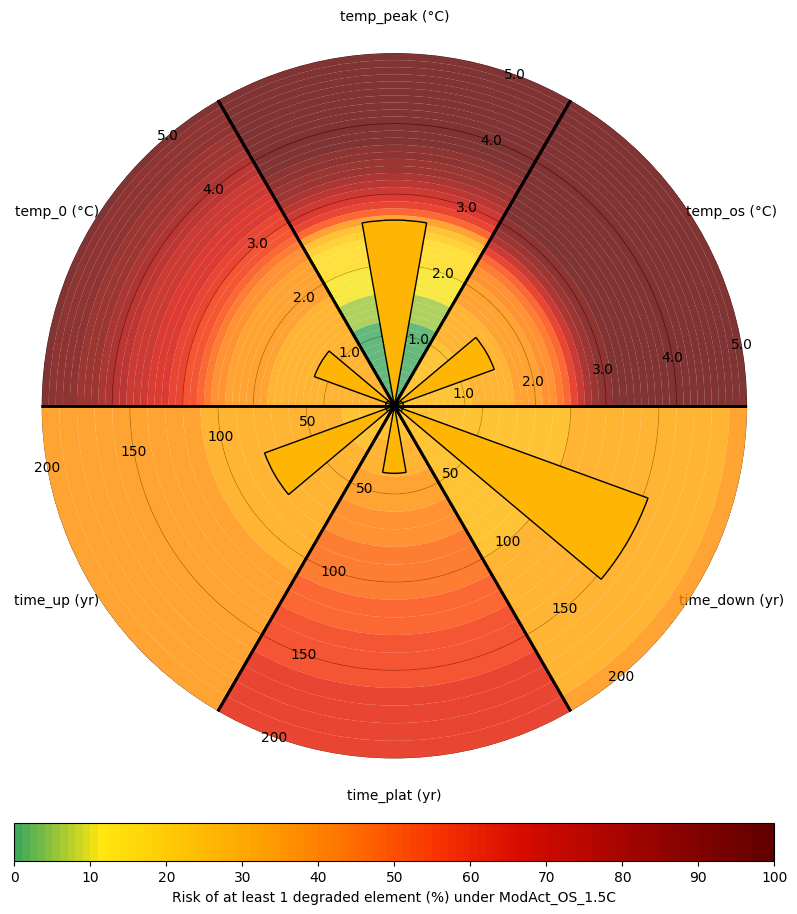

In [10]:
plotting='AR'
# baseline_disp='ssp1-2.6'

titles = ['temp_peak (°C)', 'temp_0 (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)', 'temp_os (°C)']
rticks = [np.arange(0,5.1,step=1), np.arange(0,5+.1,step=1),
           np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,5+.1,step=1)]
ylims=[(0,5), (0,5), (0,200), (0,200), (0,200), (0,5)]
N=len(popt)
outer_width = 360/N
inner_width = 2*180/3/N
width = outer_width+inner_width

fig=plt.figure(figsize=(8,9))
radar = Radar(fig, N, titles=titles, rotate_labels=False, 
              wedge_width = outer_width, with_rlabels=True, 
              ylims=ylims, rticks=rticks,loc_offset=10,wedgetick_lw=2)

sim2ax_reorder = [1,0,3,4,5,2]
AR_popt_reordered = list(map(AR_popt.__getitem__, sim2ax_reorder))
pars_reordered = list(map(pars.__getitem__,sim2ax_reorder))

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=100)
# bounds = np.arange(-0.5,9,step=1)
# norm = mpl.colors.BoundaryNorm(bounds, cmap.N)

for j, ax, angle, pr, p_val in zip(range(len(popt)), 
                            radar.axes, 
                            radar.angles,
                            pars_reordered,
                            popt[sim2ax_reorder]):
    # to_plot = AR_popt_reordered[j].mean(axis=1).max(axis=1) # Picking out the maximum 1-risk
    if plotting == 'AR':
        to_plot = AR_popt_reordered[j].mean(axis=1)[:,2300-t_ref] # Picking out the final 1-risk
        to_plot_baseline = AR_baseline.mean(axis=0)[2300-t_ref]
    else:
        to_plot = D[sim2ax_reorder[j]].sum(axis=2).mean(axis=1)[:,-1]/9
        to_plot_baseline = D_baseline.sum(axis=1).mean(axis=0)[-1]/9
    radar.wedge_stacked_bar(ax,angle,pr,
                            c_list=c_list,zorder=0,
                            c_vals=to_plot,N_col_bins=20,alpha=0.8,edgecolor=None)
    radar.wedge_stacked_bar(ax,angle,[p_val],
                            c_list=c_list,
                            width=np.deg2rad(inner_width),
                            alpha=1,edgecolor='k',zorder=2,N_col_bins=20,
                            c_vals=[to_plot_baseline])
    
    # popt_en_med = np.median(popts[:,sim2ax_reorder[j]])
    # yerr = np.array([popt_en_med-np.quantile(popts[:,sim2ax_reorder[j]],0.1),
    #                   np.quantile(popts[:,sim2ax_reorder[j]],0.9)-popt_en_med]).reshape(2,1)
    # ax.errorbar(np.deg2rad(angle),popt_en_med, 
    #             yerr=yerr,
    #             c='k',ls='',capsize=7, fmt="x",lw=0.5,capthick=0.5)


radar.draw_wedgeticks(ylims=ylims,width=radar.wedge_width,lw=2)

fig.subplots_adjust(bottom=0.2)
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap),
                    ax=radar.axes,orientation='horizontal',
                    fraction=0.1,pad=0.075,label=r'Risk of at least 1 degraded element (%) under '+baseline_disp,alpha=0.8,
                    )
cbar.set_ticks([k for k in np.arange(0,1.1,0.1)],labels=[k for k in range(0,110,10)])

fig.savefig('../../../Figures/Overshoots/NCC/SOS_%s.png'%baseline_disp,bbox_inches='tight')

## Alternative visualisation

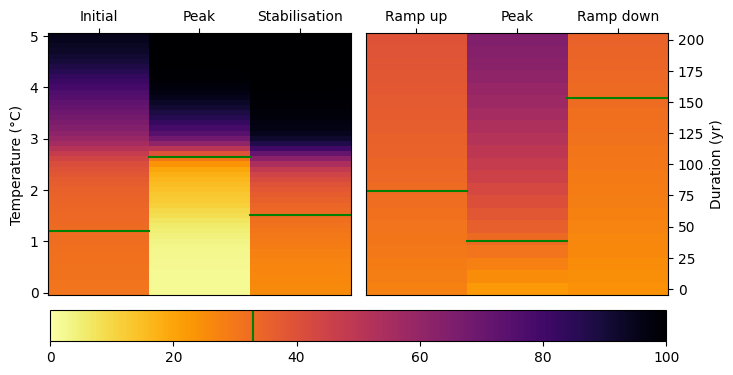

In [11]:
AR_temp = np.array([AR_popt[i] for i in range(3)])
AR_dura = np.array([AR_popt[i] for i in range(3,6)])

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = 'inferno_r'#LinearSegmentedColormap.from_list('my_cmap', c_list, N=100)
baseline_col = 'green'

fig,axs = plt.subplots(ncols=2,figsize=(8,4))
fig.subplots_adjust(wspace=0.05)

for i in range(2):
    axs[i].xaxis.tick_top()
    # axs[i].grid(axis='y')
# axs[0].set_ylim(0,5)
# axs[1].set_ylim(0,200)

axs[0].set_ylabel("Temperature (°C)")
axs[0].set_xticks([0,1,2],[r'Initial', r'Peak', r'Stabilisation'])
axs[0].imshow(100*AR_temp.mean(axis=2)[:,:,2300-t_ref].T,aspect='auto',origin='lower',
                 cmap=cmap,extent=(-0.5, 3-0.5, -.05, T_peaks.max()+0.05),vmin=0,vmax=100)

axs[1].yaxis.tick_right()
axs[1].set_ylabel("Duration (yr)")
axs[1].yaxis.set_label_position("right")
axs[1].set_xticks([0,1,2],[r'Ramp up', r'Peak', r'Ramp down'])
im=axs[1].imshow(100*AR_dura.mean(axis=2)[:,:,2300-t_ref].T,aspect='auto',origin='lower',
                 cmap=cmap,extent=(-0.5, 3-0.5, -5, t_ups.max()+5),vmin=0,vmax=100)
# fig.colorbar()

for i in range(6):
    axs[i//3].plot([i%3-0.5,i%3+0.5],[popt[i]]*2,c=baseline_col)
cb = fig.colorbar(im, ax=axs, orientation='horizontal', fraction=.1,pad=.05)
cb.ax.plot([AR_baseline.mean(axis=0)[-1]*100]*2,[0,1],c=baseline_col)

fig.savefig('../../../Figures/Overshoots/NCC/SOS_alt_%s.png'%baseline,bbox_inches='tight')

## Polar bar chart

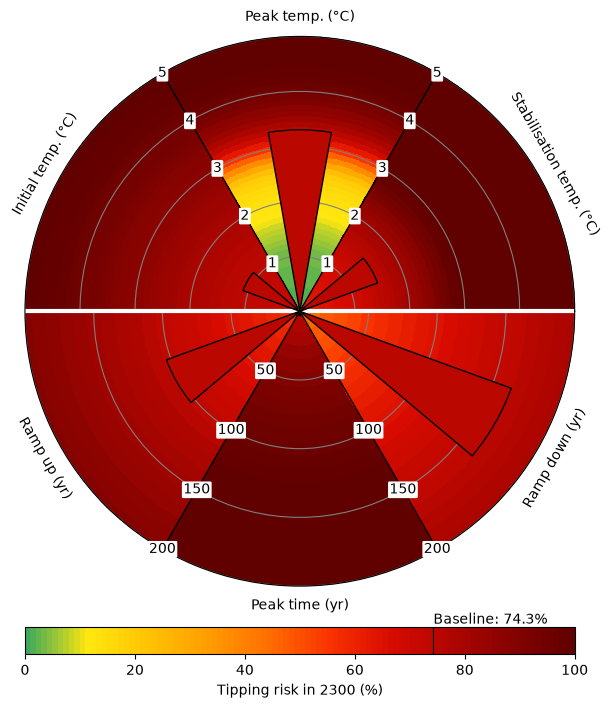

In [8]:
fig, ax = plt.subplots(figsize=(6,7), subplot_kw={'projection': 'polar'},
                        layout='constrained')
labels = ['Stabilisation temp. (°C)', 'Peak temp. (°C)', 'Initial temp. (°C)', 'Ramp up (yr)', 'Peak time (yr)', 'Ramp down (yr)']

N=len(popt)
outer_width = 360/N
inner_width = 2*180/3/N

sim2ax_reorder = [1,0,3,4,5,2]
angles_0 = np.arange(60,421,60)
theta = np.linspace(0,outer_width)

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=100)
baseline_col = cmap(TR_baseline[-1])

for i in range(6):
    j = sim2ax_reorder[i]
    to_plot = np.repeat(100*TR[j].mean(axis=-1,keepdims=True), len(theta)-1, axis=1)
    r_diff = np.diff(pars[j])[0]
    r = np.arange(pars[j][0]-r_diff/2,pars[j][-1]+r_diff,r_diff)/pars[j][-1]
    r[0]=0
    im=ax.pcolormesh(np.radians(angles_0[i]+theta), r,
                     to_plot,cmap=cmap,vmin=0,vmax=100)
    ax.bar(np.radians(angles_0[i]+outer_width/2), popt[j]/pars[j][-1], 
           color=baseline_col,
           width=np.radians(inner_width),edgecolor='k',zorder=3)
    
    
ax.set_xticks(np.radians(np.arange(0,360,outer_width)),minor=True)
ax.set_xticks(np.radians(np.arange(30,360,outer_width)),labels)
ax.tick_params(axis='x', which='major')#, pad=10)
labels = []
angles = np.arange(30,360,outer_width)
for label, angle in zip(ax.get_xticklabels(), angles):
    x,y = label.get_position()
    lab = ax.text(x,y, label.get_text(), transform=label.get_transform(),
                  ha=label.get_ha(), va=label.get_va())
    if angle < 180:
        new_angle = angle-90
    else:
        new_angle = angle+90
    lab.set_rotation(new_angle)
    labels.append(lab)
ax.set_xticklabels([])

ax.set_rticks([])
ax.set_rlim(0,1)
ax.grid(axis='x',which='minor',visible=True,lw=1,color='k')
ax.grid(axis='x',which='major',visible=False)


tick_bbox = dict(facecolor='white', 
                 edgecolor='w', 
                 boxstyle='round,pad=0.05')
tick_label_color='k'
# Temperature ticks
temp_ticks = np.arange(1,6,1)/5
for t in temp_ticks:
    ax.plot(np.linspace(0,np.pi),[t]*50,color='gray',lw=0.8,zorder=2)
    for i in range(1,3):
        ax.text(i*np.radians(outer_width),#np.pi*(1/2)-np.radians(inner_width),
                t,round(t*5),color=tick_label_color,
                ha='center',va='center',zorder=3,
                bbox=tick_bbox)

# Time ticks
time_ticks = np.arange(50,201,50)/200
for t in time_ticks:
    ax.plot(np.linspace(np.pi,2*np.pi),[t]*50,color='gray',lw=0.8,zorder=2)
    for i in range(1,3):
        ax.text(np.pi+i*np.radians(outer_width),#np.pi*(3/2)-np.radians(inner_width),
                t,round(t*200),color=tick_label_color,
                ha='center',va='center',zorder=3,
                bbox=tick_bbox)

cb = fig.colorbar(im,orientation='horizontal',label='Tipping risk in 2300 (%)',pad=0)
cb.ax.plot([TR_baseline[-1]*100]*2,[0,1],c='k',lw=0.8)
cb.ax.text(TR_baseline[-1]*100,1,
           'Baseline: '+ str(round(TR_baseline[-1]*100,1))+'%',ha='left',va='bottom')

ax.plot([0]*2,[0,1],color='white',lw=3)
ax.plot([np.pi]*2,[0,1],color='white',lw=3)
fig.savefig('../../../Figures/Overshoots/NCC/SOS_%s.pdf'%baseline,bbox_inches='tight',
            dpi=300,format='pdf')

### All three scenarios at once

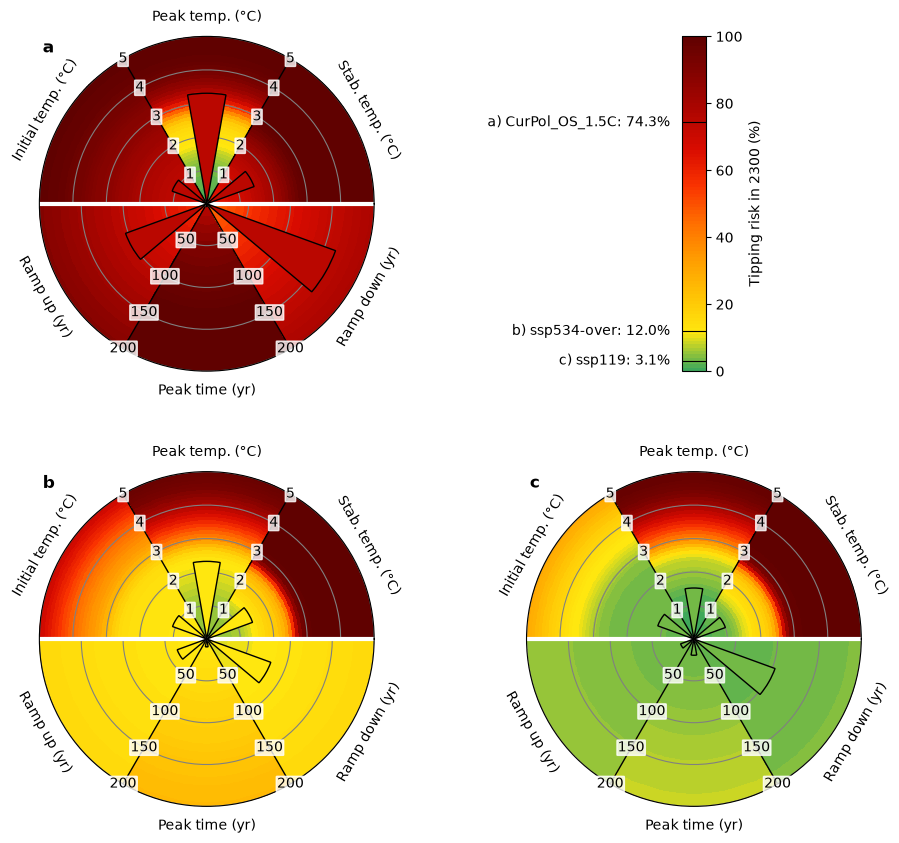

In [3]:
baselines = ['CurPol_OS_1.5C','ssp534-over','ssp119']
par_name = ['temp_init', 'temp_peak', 'temp_stab', 'time_up', 'time_peak', 'time_down']
TRs = [[np.loadtxt('../../../Data/Simulations/Overshoots/%s/OAT'%b+'/Full_TR_%s.csv'%par_name[i]) 
        for i in range(6)] 
       for b in baselines]
TRs_baseline = [k_risk(np.delete(np.loadtxt('../../../Data/Simulations/Overshoots/%s/Baseline/interactionMean_indRisk.csv'%b),
                                 6,axis=0),1,axis=0) 
                for b in baselines]
popts = [np.loadtxt('../../../Data/Simulations/Overshoots/%s/Baseline/popt.txt'%b) for b in baselines]

T_0s = np.arange(0,5.1,step=0.1)
T_peaks = np.arange(0,5.1,step=0.1)
T_oss = np.arange(0,5.1,step=0.1)

t_ups = np.arange(0,201,step=10)
t_plats = np.arange(0,201,step=10)
t_downs = np.arange(0,201,step=10)

pars = [T_0s, T_peaks, T_oss, t_ups, t_plats, t_downs]

# fig, axs = plt.subplots(figsize=(10,10), subplot_kw={'projection': 'polar'},
#                         layout='constrained',
#                         nrows=2,ncols=2)
# axs_ordered = [axs[0,0], axs[1,0], axs[1,1]]

fig = plt.figure(figsize=(12,10))
gs = GridSpec(2,2,figure=fig,hspace=0.3,wspace=0.1)
axs_ordered = []
axs_ordered.append(fig.add_subplot(gs[0,0],projection='polar'))
axs_ordered.append(fig.add_subplot(gs[1,0],projection='polar'))
axs_ordered.append(fig.add_subplot(gs[1,1],projection='polar'))

# fig.subplots_adjust(wspace=1.5)
labels = ['Stab. temp. (°C)', 'Peak temp. (°C)', 'Initial temp. (°C)', 
          'Ramp up (yr)', 'Peak time (yr)', 'Ramp down (yr)']

N=6
outer_width = 360/N
inner_width = 2*180/3/N

sim2ax_reorder = [1,0,3,4,5,2]
angles_0 = np.arange(60,421,60)
theta = np.linspace(0,outer_width)

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=100)

for k,ax in enumerate(axs_ordered):
    baseline_col = cmap(TRs_baseline[k][-1])
    for i in range(6):
        j = sim2ax_reorder[i]
        to_plot = np.repeat(100*TRs[k][j].mean(axis=-1,keepdims=True), len(theta)-1, axis=1)
        r_diff = np.diff(pars[j])[0]
        r = np.arange(pars[j][0]-r_diff/2,pars[j][-1]+r_diff,r_diff)/pars[j][-1]
        r[0]=0
        im=ax.pcolormesh(np.radians(angles_0[i]+theta), r,
                         to_plot,cmap=cmap,vmin=0,vmax=100)
        ax.bar(np.radians(angles_0[i]+outer_width/2), 
               popts[k][j]/pars[j][-1], 
               color=baseline_col,
               width=np.radians(inner_width),edgecolor='k',zorder=3)
    
    ax.set_xticks(np.radians(np.arange(0,360,outer_width)),minor=True)
    ax.set_xticks(np.radians(np.arange(30,360,outer_width)),labels)
    # ax.tick_params(axis='x', which='major')#, pad=10)
    labels = []
    angles = np.arange(30,360,outer_width)
    for label, angle in zip(ax.get_xticklabels(), angles):
        x,y = label.get_position()
        lab = ax.text(x,y, label.get_text(), transform=label.get_transform(),
                      ha=label.get_ha(), va=label.get_va())
        if angle < 180:
            new_angle = angle-90
        else:
            new_angle = angle+90
        lab.set_rotation(new_angle)
        labels.append(lab)
    ax.set_xticklabels([])
    
    ax.set_rticks([])
    ax.set_rlim(0,1)
    ax.grid(axis='x',which='minor',visible=True,lw=1,color='k')
    ax.grid(axis='x',which='major',visible=False)

    tick_bbox = dict(facecolor='white', 
                     edgecolor='w', 
                     boxstyle='round,pad=0.05',alpha=0.8)
    tick_label_color='k'
    # tick_offset
    # Temperature ticks
    temp_ticks = np.arange(1,6,1)/5
    for t in temp_ticks:
        ax.plot(np.linspace(0,np.pi),[t]*50,color='gray',lw=0.8,zorder=2)
        for i in range(1,3):
            ax.text(i*np.radians(outer_width),#np.pi*(1/2)-np.radians(inner_width),
                    t,round(t*5),color=tick_label_color,
                    ha='center',va='center',zorder=3,
                    bbox=tick_bbox)

    # Time ticks
    time_ticks = np.arange(50,201,50)/200
    for t in time_ticks:
        ax.plot(np.linspace(np.pi,2*np.pi),[t]*50,color='gray',lw=0.8,zorder=2)
        for i in range(1,3):
            ax.text(np.pi+i*np.radians(outer_width),#np.pi*(3/2)-np.radians(inner_width),
                    t,round(t*200),color=tick_label_color,
                    ha='center',va='center',zorder=3,
                    bbox=tick_bbox)

    # cb = fig.colorbar(im,orientation='horizontal',label='Tipping risk in 2300 (%)',pad=0,ax=ax)
    # cb.ax.plot([TRs_baseline[k][-1]*100]*2,[0,1],c='k',lw=0.8)
    # cb.ax.text(TRs_baseline[k][-1]*100,1,
    #            'Baseline: '+ str(round(TRs_baseline[k][-1]*100,1))+'%',ha='left',va='bottom')
    
    ax.plot([0]*2,[0,1],color='white',lw=3)
    ax.plot([np.pi]*2,[0,1],color='white',lw=3)


x0,y0,x1,y1 = gs[0,1].get_position(fig).get_points().flatten()
cbar_width = 0.02 # in fig fraction
# cax = fig.add_axes([x0,(y0+y1)/2-cbar_width/2,x1-x0,cbar_width])
cax = fig.add_axes([(x0+x1)/2-cbar_width/2,
                    y0,
                    cbar_width,
                    y1-y0])
cb = fig.colorbar(im,cax=cax,label='Tipping risk in 2300 (%)',pad=0)#,orientation='horizontal')
cax.xaxis.set_label_position('top') 
for k in range(3):
    # cb.ax.plot([TRs_baseline[k][-1]*100]*2,[0,1],c='k',lw=0.8)
    # cb.ax.text(TRs_baseline[k][-1]*100,0,
    #            'Baseline: %s'%str(round(TRs_baseline[k][-1]*100,1))+'%',ha='left',va='top')
    cb.ax.plot([0,1],[TRs_baseline[k][-1]*100]*2,c='k',lw=0.8)
    cb.ax.text(-.5,TRs_baseline[k][-1]*100,
               '%s) %s: %s'%('abc'[k],baselines[k],str(round(TRs_baseline[k][-1]*100,1)))+'%',ha='right',va='center')

for i,l in enumerate('abc'):
    axs_ordered[i].annotate(l, (0.01,0.99), ha='left',va='top',xycoords='axes fraction',weight='bold',fontsize=12)
# fig.savefig('../../../Figures/Overshoots/NCC/SOS_%s.pdf'%baseline,bbox_inches='tight',
#             dpi=300,format='pdf')

In [78]:
labels[0].get_rotation()

300.0

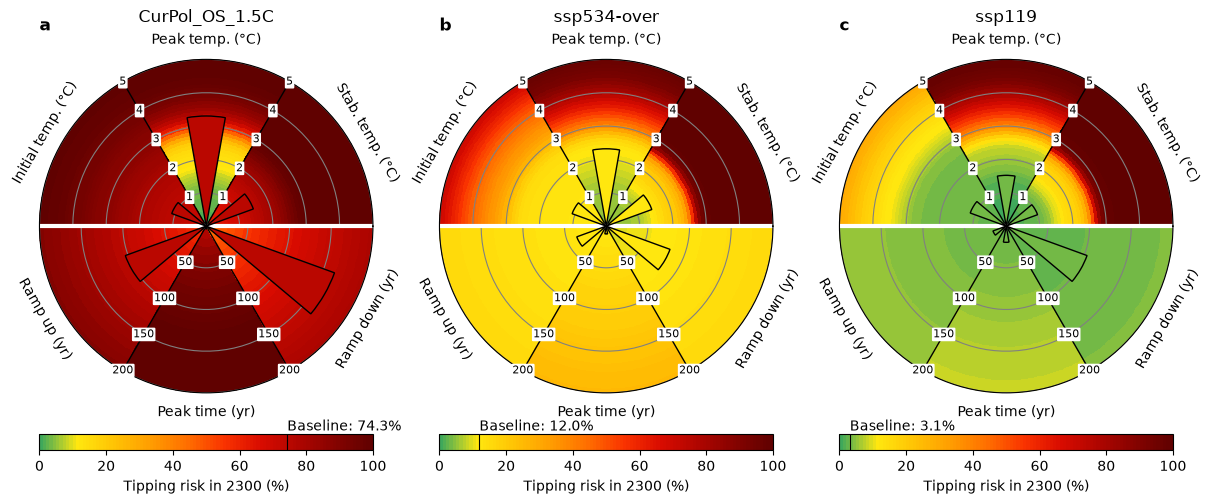

In [18]:
fig, axs = plt.subplots(figsize=(12,12), subplot_kw={'projection': 'polar'},
                        layout='constrained',
                        ncols=3)
# fig.subplots_adjust(wspace=0.5)
axs_ordered = [axs[0], axs[1], axs[2]]

labels = ['Stab. temp. (°C)', 'Peak temp. (°C)', 'Initial temp. (°C)', 
          'Ramp up (yr)', 'Peak time (yr)', 'Ramp down (yr)']

N=6
outer_width = 360/N
inner_width = 2*180/3/N

sim2ax_reorder = [1,0,3,4,5,2]
angles_0 = np.arange(60,421,60)
theta = np.linspace(0,outer_width)

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=100)

for k,ax in enumerate(axs_ordered):
    baseline_col = cmap(TRs_baseline[k][-1])
    for i in range(6):
        j = sim2ax_reorder[i]
        to_plot = np.repeat(100*TRs[k][j].mean(axis=-1,keepdims=True), len(theta)-1, axis=1)
        r_diff = np.diff(pars[j])[0]
        r = np.arange(pars[j][0]-r_diff/2,pars[j][-1]+r_diff,r_diff)/pars[j][-1]
        r[0]=0
        im=ax.pcolormesh(np.radians(angles_0[i]+theta), r,
                         to_plot,cmap=cmap,vmin=0,vmax=100)
        ax.bar(np.radians(angles_0[i]+outer_width/2), 
               popts[k][j]/pars[j][-1], 
               color=baseline_col,
               width=np.radians(inner_width),edgecolor='k',zorder=3)
    
    ax.set_xticks(np.radians(np.arange(0,360,outer_width)),minor=True)
    ax.set_xticks(np.radians(np.arange(30,360,outer_width)),labels)
    ax.tick_params(axis='x', which='major')#, pad=10)

    labels = []
    angles = np.arange(30,360,outer_width)
    for label, angle in zip(ax.get_xticklabels(), angles):
        x,y = label.get_position()
        lab = ax.text(x,y, label.get_text(), transform=label.get_transform(),
                      ha=label.get_ha(), va=label.get_va())
        if angle < 180:
            new_angle = angle-90
        else:
            new_angle = angle+90
        lab.set_rotation(new_angle)
        labels.append(lab)
    ax.set_xticklabels([])
    
    ax.set_rticks([])
    ax.set_rlim(0,1)
    ax.grid(axis='x',which='minor',visible=True,lw=1,color='k')
    ax.grid(axis='x',which='major',visible=False)

    tick_bbox = dict(facecolor='white', 
                     edgecolor='w', 
                     boxstyle='round,pad=0.05')
    tick_label_color='k'
    # Temperature ticks
    temp_ticks = np.arange(1,6,1)/5
    for t in temp_ticks:
        ax.plot(np.linspace(0,np.pi),[t]*50,color='gray',lw=0.8,zorder=2)
        for i in range(1,3):
            ax.text(i*np.radians(outer_width),#np.pi*(1/2)-np.radians(inner_width),
                    t,round(t*5),color=tick_label_color,
                    ha='center',va='center',zorder=3,
                    bbox=tick_bbox,fontsize=8)

    # Time ticks
    time_ticks = np.arange(50,201,50)/200
    for t in time_ticks:
        ax.plot(np.linspace(np.pi,2*np.pi),[t]*50,color='gray',lw=0.8,zorder=2)
        for i in range(1,3):
            ax.text(np.pi+i*np.radians(outer_width),#np.pi*(3/2)-np.radians(inner_width),
                    t,round(t*200),color=tick_label_color,
                    ha='center',va='center',zorder=3,
                    bbox=tick_bbox,fontsize=8)

    cb = fig.colorbar(im,orientation='horizontal',label='Tipping risk in 2300 (%)',pad=0,ax=ax)
    cb.ax.plot([TRs_baseline[k][-1]*100]*2,[0,1],c='k',lw=0.8)
    cb.ax.text(TRs_baseline[k][-1]*100,1,
               'Baseline: '+ str(round(TRs_baseline[k][-1]*100,1))+'%',ha='left',va='bottom')
    
    ax.plot([0]*2,[0,1],color='white',lw=3)
    ax.plot([np.pi]*2,[0,1],color='white',lw=3)
    ax.text(0.5,1.1,baselines[k],va='bottom',ha='center',transform=ax.transAxes,fontsize=12)


# cax = fig.add_subplot(gs[0,1])
# cax.set_axis_off()
# fig.colorbar(im,ax=cax,label='Tipping risk in 2300 (%)',pad=0)

for i,l in enumerate('abc'):
    axs_ordered[i].annotate(l, (-0,1.1), ha='left',va='center',xycoords='axes fraction',weight='bold',fontsize=12)
fig.savefig('../../../Figures/Overshoots/Submission/OAT_3_sos.pdf',bbox_inches='tight',
            dpi=300,format='pdf')

In [13]:
ax.get_xticklabels()

[Text(0.5235987755982988, 0, ''),
 Text(1.5707963267948966, 0, ''),
 Text(2.6179938779914944, 0, ''),
 Text(3.6651914291880923, 0, ''),
 Text(4.71238898038469, 0, ''),
 Text(5.759586531581287, 0, '')]

In [39]:
gs[0,1].get_position(fig).get_points()

array([[0.53095238, 0.54521739],
       [0.9       , 0.88      ]])

## Extended Data

(0.0, 200.0)

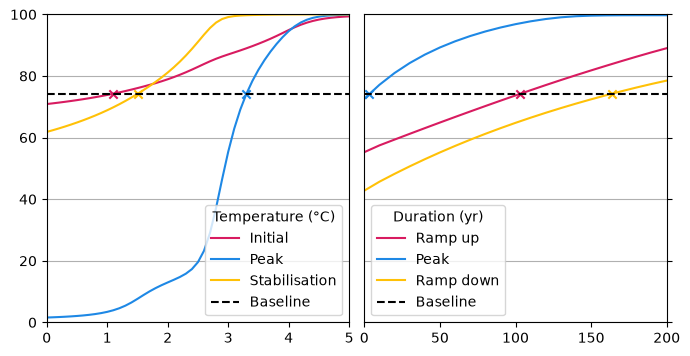

In [3]:
fig,axs = plt.subplots(ncols=2,figsize=(8,4),sharey=True)
fig.subplots_adjust(wspace=0.05)
axs[1].yaxis.tick_right()

labels = ['Initial', 'Peak', 'Stabilisation', 'Ramp up ', 'Peak', 'Ramp down']
colors = ['#D81B60', '#1E88E5', '#FFC107']
for i in range(3):
    for j in range(2):
        axs[j].plot(pars[i+3*j],TR[i+3*j].mean(axis=1)*100,color=colors[i],label=labels[i+3*j])
        axs[j].scatter(popt[i+3*j],TR_baseline[-1]*100,color=colors[i],marker='x')
axs[0].plot([0,5],[100*TR_baseline[-1]]*2,ls='--',c='k',label='Baseline')
axs[1].plot([0,200],[100*TR_baseline[-1]]*2,ls='--',c='k',label='Baseline')
axs[0].grid(axis='y')
axs[1].grid(axis='y')

axs[0].legend(title='Temperature (°C)')
axs[1].legend(title='Duration (yr)')

axs[0].set_ylim(0,100)
axs[0].set_xlim(0,5)
axs[1].set_xlim(0,200)

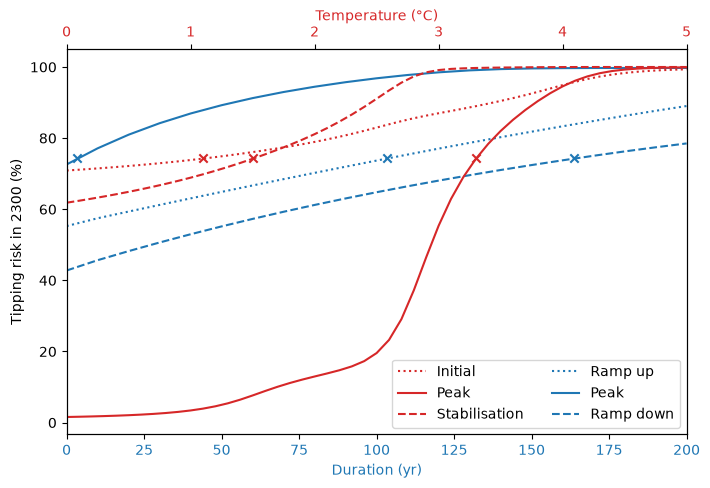

In [69]:
fig,ax_time=plt.subplots(figsize=(8,5))
# ax_temp.set_ylim(0,100)
ax_time.set_ylabel('Tipping risk in 2300 (%)')
ax_time.set_xlim(0,200)

ax_temp = ax_time.twiny()
ax_temp.set_xlim(0,5)
axs = [ax_temp,ax_time]

labels = ['Initial', 'Peak', 'Stabilisation', 'Ramp up ', 'Peak', 'Ramp down']
colors = ['tab:red','tab:blue']
ls=[':','-','--']
axis_labels = ['Temperature (°C)', 'Duration (yr)']

leg_h = []
leg_l = []
for j in range(2):
    axs[j].tick_params(axis='x', labelcolor=colors[j])
    axs[j].set_xlabel(axis_labels[j],color=colors[j])
    for i in range(3):
        axs[j].plot(pars[i+3*j],TR[i+3*j].mean(axis=1)*100,
                    color=colors[j],label=labels[i+3*j],ls=ls[i])
        axs[j].scatter(popt[i+3*j],TR_baseline[-1]*100,
                       color=colors[j],marker='x')
    h,l = axs[j].get_legend_handles_labels()
    leg_h+= h
    leg_l+= l
axs[1].legend(leg_h,leg_l,loc='lower right', ncols=2)
# axs[0].legend(title='Temperature (°C)',loc='upper left')
# axs[1].legend(loc='lower right',title='Duration (yr)')

In [98]:
df_TEs.index.values

array(['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS',
       'WAM'], dtype=object)

In [102]:
D_mean[0].shape

(51, 9)

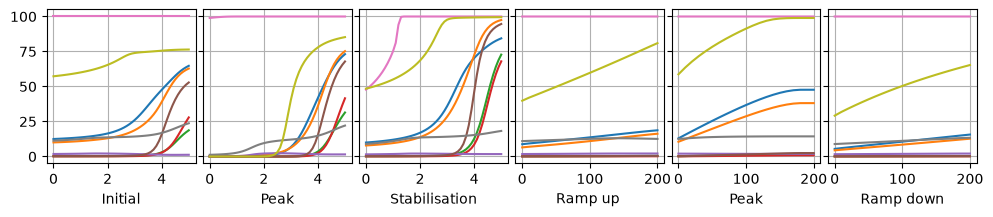

In [122]:
fig,axs=plt.subplots(ncols=6,sharey=True,figsize=(12,2))
fig.subplots_adjust(wspace=0.05)
# axs[0].set_yscale('log')
labels = ['Initial', 'Peak', 'Stabilisation', 'Ramp up ', 'Peak', 'Ramp down']
TEs = ['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS','WAM']
for i in range(6):
    axs[i].set_xlabel(labels[i])
    axs[i].grid(axis='both')
    for j in range(9):
        axs[i].plot(pars[i],D_mean[i][:,j]*100,label=TEs[j])

In [4]:
baselines = ['CurPol_OS_1.5C','ssp534-over','ssp119']
par_name = ['temp_init', 'temp_peak', 'temp_stab', 'time_up', 'time_peak', 'time_down']
TRs = [[np.loadtxt('../../../Data/Simulations/Overshoots/%s/OAT'%b+'/Full_TR_%s.csv'%par_name[i]) 
        for i in range(6)] 
       for b in baselines]
TRs_baseline = [k_risk(np.delete(np.loadtxt('../../../Data/Simulations/Overshoots/%s/Baseline/interactionMean_indRisk.csv'%b),
                                 6,axis=0),1,axis=0) 
                for b in baselines]
D_mean = [[np.loadtxt('../../../Data/Simulations/Overshoots/%s/OAT'%b+
                      '/Full_indiMean_%s.csv'%p) for p in par_name] for b in baselines]
popts = [np.loadtxt('../../../Data/Simulations/Overshoots/%s/Baseline/popt.txt'%b) for b in baselines]

T_0s = np.arange(0,5.1,step=0.1)
T_peaks = np.arange(0,5.1,step=0.1)
T_oss = np.arange(0,5.1,step=0.1)

t_ups = np.arange(0,201,step=10)
t_plats = np.arange(0,201,step=10)
t_downs = np.arange(0,201,step=10)

pars = [T_0s, T_peaks, T_oss, t_ups, t_plats, t_downs]

TEs=pd.read_excel('../../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25').index.values

## Individual sensitivity

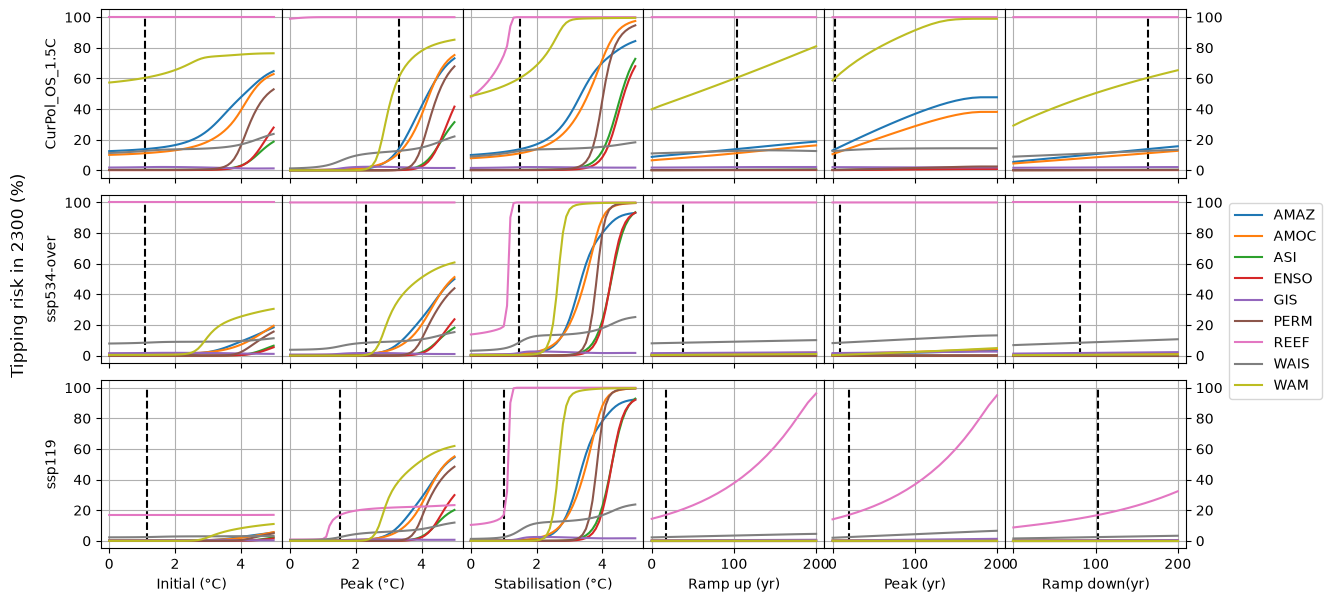

In [29]:
fig = plt.figure(figsize=(14,7))
gs = GridSpec(1, 2, figure=fig,wspace=0.0)
gs_temp = mpl.gridspec.GridSpecFromSubplotSpec(3,3,subplot_spec=gs[0],hspace=0.1,wspace=0.0)
gs_time = mpl.gridspec.GridSpecFromSubplotSpec(3,3,subplot_spec=gs[1],hspace=0.1,wspace=0.0)

axs_temp = np.array([[fig.add_subplot(gs_temp[i,j]) for j in range(3)] for i in range(3)])
axs_time = np.array([[fig.add_subplot(gs_time[i,j]) for j in range(3)] for i in range(3)])
axs = [axs_temp,axs_time]

fig.supylabel('Tipping risk in 2300 (%)',position=(0.06,0.5))
# fig.text(0.25,0.06,'Temperature (°C)',position=(0.25,0.06),ha='center')
# fig.text(0.25,0.06,'Duration (yr)',position=(0.75,0.06),ha='center')

labels = ['Initial (°C)', 'Peak (°C)', 'Stabilisation (°C)', 'Ramp up (yr)', 'Peak (yr)', 'Ramp down(yr)']

for i in range(3):
    for k in range(2):
        for j in range(3):
            a = axs[k][i,j]
            # a.set_yscale('log')
            # a.set_ylim(0.05,150)
            a.set_ylim(-5,105)

            a.set_xticklabels([])
            a.set_yticklabels([])
            a.grid()
            a.plot([popts[i][j+3*k]]*2,[0,100],color='k',ls='--')
            a.tick_params(axis='y',length=0)
            for t in range(9):
                a.plot(pars[j+3*k],100*D_mean[i][j+3*k][:,t],label=TEs[t])
        axs[k][i,-k].set_yticks(np.arange(0,101,20),np.arange(0,101,20))
        axs[k][i,-k].tick_params(axis='y',length=3.5)
    
    axs[0][i,0].set_ylabel(baselines[i])

leg_h,leg_l = axs_temp[-1,0].get_legend_handles_labels()
fig.legend(leg_h,leg_l,loc='center right'),#ncols=9)

for j in range(3):
    axs[1][j,-1].yaxis.tick_right()
    for k in range(2):
        axs[k][-1,j].set_xlabel(labels[j+3*k])
    # axs[0][j,0].set_yticks(np.arange(0,101,20),np.arange(0,101,20))
    axs[0][-1,j].set_xticks(np.arange(0,6,2),np.arange(0,6,2))
    axs[1][-1,j].set_xticks(np.arange(0,201,100),np.arange(0,201,100))

# plt.tight_layout()

## Gradients

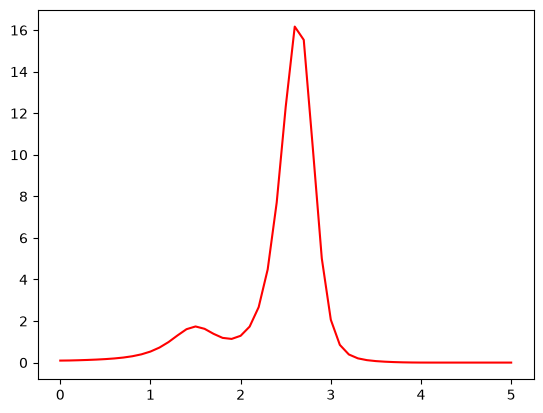

In [17]:
k=1
i=2
grad = np.gradient(TRs[k][i],pars[i],axis=0)*100
# plt.fill_between(pars[2],grad.mean(axis=1)-grad.std(axis=1),grad.mean(axis=1)+grad.std(axis=1),color='b',alpha=0.9)
plt.plot(pars[2],grad.mean(axis=1)/10,c='r')

Text(0, 0.5, 'Time sensitivity (% / dec)')

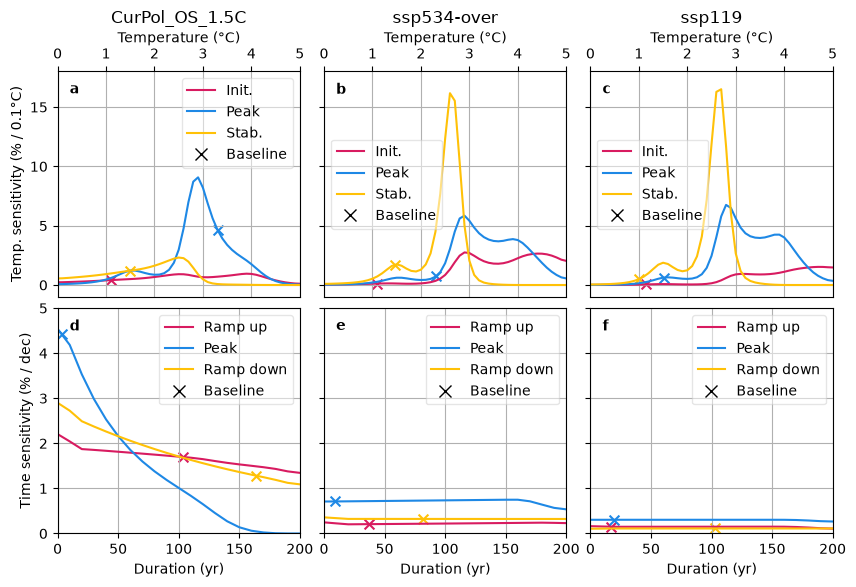

In [115]:
fig,axs=plt.subplots(nrows=2,ncols=3,figsize=(10,6))
fig.subplots_adjust(wspace=0.1,hspace=0.05)
labels = ['Init.', 'Peak', 'Stab.', 'Ramp up', 'Peak', 'Ramp down']
ylims = [(-1,18),(0,5)]
colors = ['#D81B60', '#1E88E5', '#FFC107']
locs = ['best']*6
locs[1:2] = ['center left']*2

for k,TR in enumerate(TRs):
    axs[0,k].set_title(baselines[k])
    for i,tr in enumerate(TR):
        if i <3:
            conversion = 100*0.1 # UNITS -> % / 0.1C
        else:
            conversion = 100*10 # UNITS -> % / decade
        p = popts[k][i]
        grad = conversion*np.gradient(tr.mean(axis=1),pars[i],axis=0)
        
        axs[i//3,k].plot(pars[i], grad,label=labels[i],color=colors[i%3])
        axs[i//3,k].scatter(popts[k][i],np.interp(p,pars[i],grad),marker='x',color=colors[i%3],s=50)

for i,l in enumerate('abcdef'):
    axs[i//3,i%3].annotate(l, (0.05,0.95), ha='left',va='top',xycoords='axes fraction',weight='bold')

for k in range(3):
    axs[0,k].xaxis.tick_top()
    axs[0,k].xaxis.set_label_position('top') 
    axs[0,k].set_xlim(0,5)
    axs[0,k].set_xlabel('Temperature (°C)')
    axs[0,k].set_yticks(np.arange(0,21,5))
    axs[0,k].set_ylim(ylims[0])

    axs[1,k].set_xlim(0,200)
    axs[1,k].set_xlabel('Duration (yr)')
    axs[1,k].set_ylim(ylims[1])
    for i in range(2):
        h,l = axs[i,k].get_legend_handles_labels()
        h += [Line2D([], [], color='k', marker='x', linestyle='None',
                          markersize=8, label='Baseline')]
        l += ['Baseline']
        axs[i,k].legend(h,l,loc=locs[i*3+k],framealpha=0.5)#title=baselines[k])
        axs[i,k].grid()
        if k > 0:
            axs[i,k].yaxis.set_tick_params(labelleft=False)

axs[0,0].set_ylabel('Temp. sensitivity (% / 0.1°C)')
axs[1,0].set_ylabel('Time sensitivity (% / dec)')

# fig.savefig('../../../Figures/Overshoots/Submission/OAT_sensitivities.pdf',bbox_inches='tight',
#             dpi=300,format='pdf')

In [48]:
notation = [r'$\Delta T_0$',r'$\Delta T_p$',r'$\Delta T_s$',
            r'$t_u$',r'$t_p$',r'$t_d$']
for i in range(6):
    s = '%s-max: '%notation[i]
    for k in range(3):
        local_max = sp.signal.argrelextrema(np.gradient(TRs[k][i].mean(axis=1)), np.greater)
        s+= '%s &'%str(pars[i][local_max])
    print(s)
# print(local_max)
# print(pars[i][local_max])

$\Delta T_0$-max: [2.5 3.9] &[1.3 2.9 4.4] &[1.5 3.1 4.7] &
$\Delta T_p$-max: [1.6 2.9] &[1.5 2.9 3.9] &[1.6 2.8 3.9] &
$\Delta T_s$-max: [2.5] &[1.5 2.6] &[1.5 2.7] &
$t_u$-max: [] &[180] &[150] &
$t_p$-max: [] &[160] &[150] &
$t_d$-max: [] &[30] &[] &


In [40]:
i = 1
k = 1
r=128
local_max = sp.signal.argrelextrema(np.gradient(TRs[k][i][:,r],axis=0), np.greater,axis=0)

In [41]:
local_max

(array([15, 29, 39]),)

Text(0, 0.5, 'Tipping risk (%)')

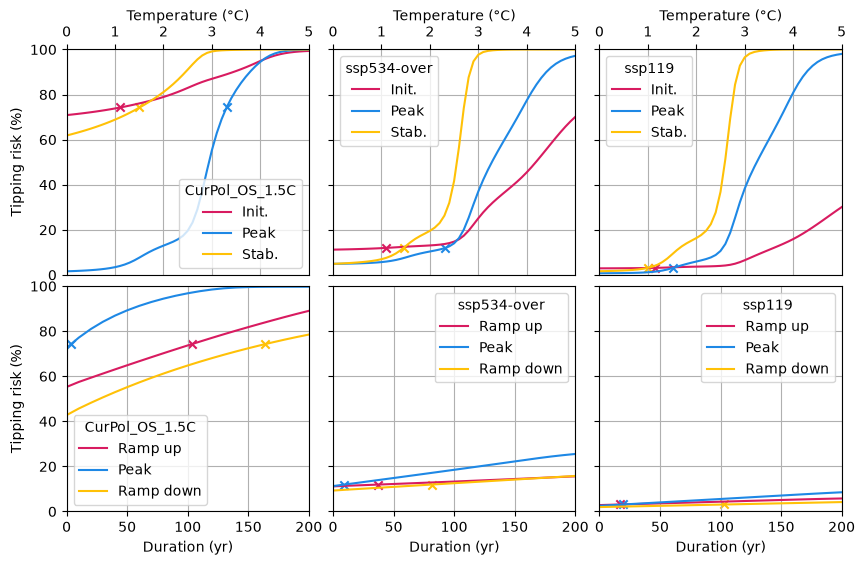

In [117]:
fig,axs=plt.subplots(nrows=2,ncols=3,figsize=(10,6),sharey=True)
fig.subplots_adjust(wspace=0.1,hspace=0.05)
labels = ['Init.', 'Peak', 'Stab.', 'Ramp up', 'Peak', 'Ramp down']
colors = ['#D81B60', '#1E88E5', '#FFC107']
axs[0,0].set_ylim(0,100)
for k,TR in enumerate(TRs):
    # axs[0,k].set_title(baselines[k])
    for i,tr in enumerate(TR):
        axs[i//3,k].plot(pars[i], 100*tr.mean(axis=1),label=labels[i],color=colors[i%3])
        axs[i//3,k].scatter(popts[k][i],TRs_baseline[k][-1]*100,color=colors[i%3],marker='x')

for k in range(3):
    axs[0,k].xaxis.tick_top()
    axs[0,k].xaxis.set_label_position('top') 
    axs[0,k].set_xlim(0,5)
    axs[0,k].set_xlabel('Temperature (°C)')

    axs[1,k].set_xlim(0,200)
    axs[1,k].set_xlabel('Duration (yr)')
    for i in range(2):
        axs[i,k].legend(title=baselines[k])
        axs[i,k].grid()
        if k > 0:
            axs[i,k].yaxis.set_tick_params(labelleft=False)

axs[0,0].set_ylabel('Tipping risk (%)')
axs[1,0].set_ylabel('Tipping risk (%)')

## Printing values to create LaTeX tables

In [201]:
notation = [r'$\Delta T_0$',r'$\Delta T_p$',r'$\Delta T_s$',
            r'$t_u$',r'$t_p$',r'$t_d$']

crit_risk = 0.05

for i in range(6):
    max_vals = []
    for k in range(3):
        tr = TRs[2-k][i].mean(axis=1)
        l = len(tr[tr<crit_risk])
        if l==0:
            max_vals += [np.nan]
        else:
            max_vals += [pars[i][l-1]]
    if i < 3:
        print('& '+notation[i]+' & %.1f & %.1f & %.1f \\\\'%tuple(max_vals))
    else:
        print('& '+notation[i]+' & %.0f & %.0f & %.0f \\\\'%tuple(max_vals))

& $\Delta T_0$ & 2.8 & nan & nan \\
& $\Delta T_p$ & 1.8 & 0.3 & 1.2 \\
& $\Delta T_s$ & 1.2 & 0.1 & nan \\
& $t_u$ & 140 & nan & nan \\
& $t_p$ & 80 & nan & nan \\
& $t_d$ & 200 & nan & nan \\


In [212]:
notation = [r'$\Delta T_0$',r'$\Delta T_p$',r'$\Delta T_s$',
            r'$t_u$',r'$t_p$',r'$t_d$']

crit_risk = 0.05
# i = 1
crit_risks = [0.05,0.1,0.2]
for i in range(6):
    print('\multirow{3}{*}{%s (°C)} '%notation[i])
    for cr in crit_risks:
        max_vals = []
        for k in range(3):
            tr = TRs[2-k][i].mean(axis=1)
            l = len(tr[tr<cr])
            if l==0:
                max_vals += [np.nan]
            else:
                max_vals += [pars[i][l-1]]
        if i < 3:
            s = '& %d & %.1f & %.1f & %.1f \\\\'%tuple([cr*100]+max_vals)
        else:
            s = '& %d & %.0f & %.0f & %.0f \\\\'%tuple([cr*100]+max_vals)
        print(s.replace('nan','*'))
    print(r'\hline')

\multirow{3}{*}{$\Delta T_0$ (°C)} 
& 5 & 2.8 & * & * \\
& 10 & 3.3 & * & * \\
& 20 & 4.3 & 2.8 & * \\
\hline
\multirow{3}{*}{$\Delta T_p$ (°C)} 
& 5 & 1.8 & 0.3 & 1.2 \\
& 10 & 2.4 & 1.9 & 1.6 \\
& 20 & 2.7 & 2.6 & 2.5 \\
\hline
\multirow{3}{*}{$\Delta T_s$ (°C)} 
& 5 & 1.2 & 0.1 & * \\
& 10 & 1.5 & 1.3 & * \\
& 20 & 2.2 & 2.0 & * \\
\hline
\multirow{3}{*}{$t_u$ (°C)} 
& 5 & 140 & * & * \\
& 10 & 200 & * & * \\
& 20 & 200 & 200 & * \\
\hline
\multirow{3}{*}{$t_p$ (°C)} 
& 5 & 80 & * & * \\
& 10 & 200 & * & * \\
& 20 & 200 & 120 & * \\
\hline
\multirow{3}{*}{$t_d$ (°C)} 
& 5 & 200 & * & * \\
& 10 & 200 & 20 & * \\
& 20 & 200 & 200 & * \\
\hline


<>:8: SyntaxWarning: invalid escape sequence '\m'
<>:8: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_42973/4249758575.py:8: SyntaxWarning: invalid escape sequence '\m'
  print('\multirow{3}{*}{%s (°C)} '%notation[i])


In [33]:
# Estimates for temp/time sensitivity at the baseline value
notation = [r'$\Delta T_0$',r'$\Delta T_p$',r'$\Delta T_s$',
            r'$t_u$',r'$t_p$',r'$t_d$']
for i in range(6):
    s = '%s '%notation[i]
    if i <3:
        conversion = 100*0.1 # UNITS: % / 0.1C
    else:
        conversion = 100*10 # UNITS: % / dec
    for k in range(3):
        p = popts[2-k][i]
        tr = TRs[2-k][i].mean(axis=1)
        grad = np.gradient(tr,pars[i])*conversion
        s += r'& %.3g'%np.interp(p,pars[i],grad)
    s += '\\\\'
    print(s)
# print(r'%s: %.3g $\pm$ %.3f'%(notation[i],sens.mean(),sens.std()))

$\Delta T_0$ & 0.0482& 0.118& 0.411\\
$\Delta T_p$ & 0.624& 0.775& 4.64\\
$\Delta T_s$ & 0.492& 1.68& 1.21\\
$t_u$ & 0.151& 0.208& 1.7\\
$t_p$ & 0.304& 0.711& 4.42\\
$t_d$ & 0.111& 0.323& 1.28\\


In [31]:
for i in range(6):
    s = '%s '%notation[i]
    for k in range(3):
        p = popts[2-k][i]
        j = np.argmax(pars[i][pars[i]<p])
        tr = TRs[2-k][i].mean(axis=1)
        grad = np.gradient(tr,pars[i])
        s += r'& [%.3g, %.3g]'%(grad[j],grad[j+1])
    s += '\\\\'
    print(s)

$\Delta T_0$ & [0.00434, 0.00534]& [0.0108, 0.0119]& [0.0411, 0.0435]\\
$\Delta T_p$ & [0.0617, 0.0647]& [0.0701, 0.109]& [0.465, 0.393]\\
$\Delta T_s$ & [0.0491, 0.0705]& [0.161, 0.174]& [0.121, 0.127]\\
$t_u$ & [0.000156, 0.000149]& [0.000206, 0.000208]& [0.0017, 0.00168]\\
$t_p$ & [0.000304, 0.000304]& [0.00071, 0.000711]& [0.00454, 0.00418]\\
$t_d$ & [0.000111, 0.000111]& [0.000323, 0.000323]& [0.00131, 0.00125]\\


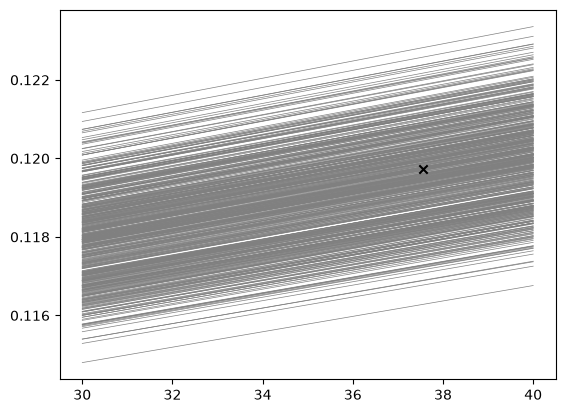

In [28]:
k = 1
i = 3
p = popts[2-k][i]
j = np.argmax(pars[i][pars[i]<p])
# for x in range(j-1,j+3):
#     if i < 3:
#         loc = x/10
#     else:
#         loc = x*10
#     plt.scatter([loc]*500,TRs[2-k][i][x,:])
#     plt.scatter([loc]*500,TRs[2-k][i][x,:])
#     plt.scatter([loc],TRs[2-k][i][x,:].mean(),marker='x',c='green')

for r in range(500):
    plt.plot(pars[i][j:j+2],TRs[2-k][i][j:j+2,r],c='gray',lw=0.5,zorder=0)

plt.scatter(popts[2-k][i],TRs_baseline[2-k][-1],marker='x',c='k',zorder=2)

In [26]:
len(popts)

3

In [248]:
finite_diff_3(pars[i][27:30],TRs[0][i][27:30,:].mean(axis=1)*100)

np.float64(87.09471610489456)

In [12]:
notation = [r'$\Delta T_0$',r'$\Delta T_p$',r'$\Delta T_s$',
            r'$t_u$',r'$t_p$',r'$t_d$']
print(baselines)
for i in range(3,6):
    s = '%s: '%notation[i]
    for k in range(3):
        s+='%.3g & '%(TRs[k][i][-1,:].mean()*100)
    print(s)

for k in range(3):
    s = '%s: '%baselines[k]
    for i in range(3,6):
        s+=r'%s $\in$ [%.3g, %.3g] &'%(notation[i],TRs[k][i][0,:].mean()*100,TRs[k][i][-1,:].mean()*100)
    print(s)

['CurPol_OS_1.5C', 'ssp534-over', 'ssp119']
$t_u$: 89 & 15.6 & 5.78 & 
$t_p$: 99.7 & 25.5 & 8.53 & 
$t_d$: 78.5 & 15.8 & 4.18 & 
CurPol_OS_1.5C: $t_u$ $\in$ [55.3, 89] &$t_p$ $\in$ [72.6, 99.7] &$t_d$ $\in$ [42.8, 78.5] &
ssp534-over: $t_u$ $\in$ [11.1, 15.6] &$t_p$ $\in$ [11.3, 25.5] &$t_d$ $\in$ [9.28, 15.8] &
ssp119: $t_u$ $\in$ [2.84, 5.78] &$t_p$ $\in$ [2.51, 8.53] &$t_d$ $\in$ [1.97, 4.18] &


## 6x6 matrix / table of derivative ratios

In [162]:
baseline_grads = np.zeros([3,6])
conversion = [100*0.1]*3+[100*1]*3
for k in range(3):
    for i,p,tr,par in zip(range(6),popts[k],TRs[k],pars):
        grad = conversion[i]*np.gradient(tr.mean(axis=1),par,axis=0)
        baseline_grads[k,i] = np.interp(p,par,grad)

grad_ratios = np.expand_dims(baseline_grads,axis=2)/np.expand_dims(baseline_grads,axis=1)

In [205]:
print(' & %s & %s & %s \\\\'%tuple(baselines))
for i in range(6):
    str_formats = [notation[i]] + ['%.3g']*3 
    s = ' & '.join(s_f for s_f in str_formats) + '\\\\'
    print(s%tuple(baseline_grads[:,i]) )

 & CurPol_OS_1.5C & ssp534-over & ssp119 \\
$\Delta T_0$ & 0.411 & 0.118 & 0.0482\\
$\Delta T_p$ & 4.64 & 0.775 & 0.624\\
$\Delta T_s$ & 1.21 & 1.68 & 0.492\\
$t_u$ & 0.17 & 0.0208 & 0.0151\\
$t_p$ & 0.442 & 0.0711 & 0.0304\\
$t_d$ & 0.128 & 0.0323 & 0.0111\\


In [165]:
tuple(baseline_grads[k,:])

['CurPol_OS_1.5C', 'ssp534-over', 'ssp119']


In [179]:
notation = [r'$\Delta T_0$',r'$\Delta T_p$',r'$\Delta T_s$',
            r'$t_u$',r'$t_p$',r'$t_d$']
for k in range(3):
    print('\\hline %s & '%baselines[k] + ' & '.join(n for n in notation) +'\\\\')
    for i in range(6):
        str_formats = ['%s'] + ['%.2f']*3 + ['%d']*3
        str_formats[i+1] = ''
        s = ' & '.join(s_f for s_f in str_formats) + '\\\\'
        arr = np.delete(grad_ratios[k,i,:] * np.array([0.1,0.1,0.1,10,10,10]),i)
        arr = tuple([notation[i]] + list(arr))
        print(s%arr)

\hline CurPol_OS_1.5C & $\Delta T_0$ & $\Delta T_p$ & $\Delta T_s$ & $t_u$ & $t_p$ & $t_d$\\
$\Delta T_0$ &  & 0.01 & 0.03 & 24 & 9 & 32\\
$\Delta T_p$ & 1.13 &  & 0.38 & 273 & 104 & 361\\
$\Delta T_s$ & 0.29 & 0.03 &  & 71 & 27 & 94\\
$t_u$ & 0.04 & 0.00 & 0.01 &  & 3 & 13\\
$t_p$ & 0.11 & 0.01 & 0.04 & 26 &  & 34\\
$t_d$ & 0.03 & 0.00 & 0.01 & 7 & 2 & \\
\hline ssp534-over & $\Delta T_0$ & $\Delta T_p$ & $\Delta T_s$ & $t_u$ & $t_p$ & $t_d$\\
$\Delta T_0$ &  & 0.02 & 0.01 & 56 & 16 & 36\\
$\Delta T_p$ & 0.66 &  & 0.05 & 373 & 108 & 239\\
$\Delta T_s$ & 1.43 & 0.22 &  & 809 & 236 & 519\\
$t_u$ & 0.02 & 0.00 & 0.00 &  & 2 & 6\\
$t_p$ & 0.06 & 0.01 & 0.00 & 34 &  & 21\\
$t_d$ & 0.03 & 0.00 & 0.00 & 15 & 4 & \\
\hline ssp119 & $\Delta T_0$ & $\Delta T_p$ & $\Delta T_s$ & $t_u$ & $t_p$ & $t_d$\\
$\Delta T_0$ &  & 0.01 & 0.01 & 31 & 15 & 43\\
$\Delta T_p$ & 1.29 &  & 0.13 & 413 & 205 & 561\\
$\Delta T_s$ & 1.02 & 0.08 &  & 325 & 161 & 442\\
$t_u$ & 0.03 & 0.00 & 0.00 &  & 4 & 13\\
$t_p$ & 

In [186]:
print((TRs_baseline[k].shape))

(451,)


In [200]:
k=0
tr_b = TRs_baseline[k][-1]
for i in range(6):
    tr= TRs[k][i].mean(axis=1)*100
    print(np.argmin(np.abs(tr-tr_b-baseline_grads[k,i])))

0
13
0
0
0
0


In [195]:
tr.shape

(21, 500)